# Atividade avaliativa — KNN com a base Iris
Mineração de Dados · Aula 7 · Profa. Ana Paula

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

## 1. Base Iris

In [2]:
iris = load_iris(as_frame=True)
X, y = iris.data, iris.target
display(X.describe().round(2))
print(y.value_counts().sort_index().rename(index=dict(enumerate(iris.target_names))))

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


target
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


- `sepal length` / `sepal width`: comprimento e largura da **sépala**, em cm.
- `petal length` / `petal width`: comprimento e largura da **pétala**, em cm.
- **Classe-alvo** (`target`): espécie da flor: 0 = setosa, 1 = versicolor, 2 = virginica, com 50 flores cada.

## 2. Treino (75%) e teste (25%)

In [3]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, random_state=123, stratify=y)
print(len(X_treino), 'flores de treino |', len(X_teste), 'flores de teste')

112 flores de treino | 38 flores de teste


## 3. Pipeline

In [4]:
modelo = Pipeline([('escala', StandardScaler()), ('knn', KNeighborsClassifier())])
modelo

Pipeline(steps=[('escala', StandardScaler()), ('knn', KNeighborsClassifier())])

## 4. Acurácia de treino por K

In [5]:
valores_k = [1, 3, 5, 7, 9, 11, 15]
tabela_k = pd.DataFrame({'K': valores_k, 'acurácia treino': [
    clone(modelo).set_params(knn__n_neighbors=k).fit(X_treino, y_treino).score(X_treino, y_treino)
    for k in valores_k]})
tabela_k.round(3)

,K,acurácia treino
0,1,1.000
1,3,0.946
2,5,0.955
3,7,0.955
4,9,0.955
5,11,0.955
6,15,0.946


## 5. Seleção dos parâmetros: validação cruzada com 5 folds, só no treino

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
grade = {'knn__n_neighbors': valores_k,
         'knn__weights': ['uniform', 'distance'],
         'knn__p': [1, 2]}                      # p=1 Manhattan, p=2 euclidiana
busca = GridSearchCV(modelo, grade, cv=cv, scoring='accuracy').fit(X_treino, y_treino)
print('Melhores parâmetros:', busca.best_params_)
print('Acurácia média na validação:', round(busca.best_score_, 3))

Melhores parâmetros: {'knn__n_neighbors': 15, 'knn__p': 2, 'knn__weights': 'distance'}
Acurácia média na validação: 0.956


## 6. Avaliação do melhor modelo no teste (uma única vez)

Acurácia: 0.974
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        12
  versicolor      1.000     0.923     0.960        13
   virginica      0.929     1.000     0.963        13

    accuracy                          0.974        38
   macro avg      0.976     0.974     0.974        38
weighted avg      0.976     0.974     0.974        38



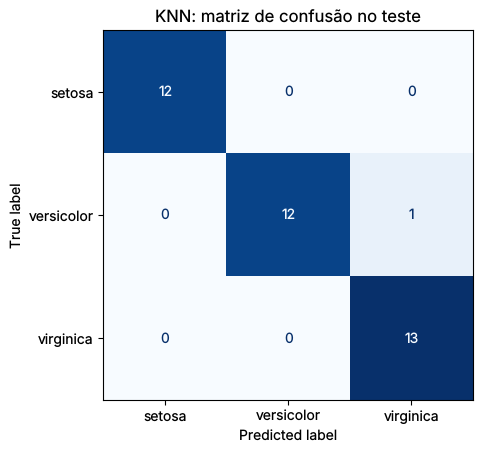

In [7]:
y_prev = busca.predict(X_teste)
print('Acurácia:', round(accuracy_score(y_teste, y_prev), 3))
print(classification_report(y_teste, y_prev, target_names=iris.target_names, digits=3))
ConfusionMatrixDisplay.from_predictions(y_teste, y_prev, display_labels=iris.target_names,
                                        cmap='Blues', colorbar=False)
plt.title('KNN: matriz de confusão no teste')
plt.show()

## 7. Pesos uniformes × distância e euclidiana × Manhattan

configuração,distância + Manhattan,distância + euclidiana,uniforme + Manhattan,uniforme + euclidiana
K,,,,
1,0.910,0.920,0.910,0.920
3,0.938,0.946,0.938,0.946
5,0.946,0.947,0.946,0.938
7,0.955,0.947,0.955,0.947
9,0.947,0.947,0.947,0.946
11,0.955,0.947,0.955,0.938
15,0.946,0.956,0.938,0.929


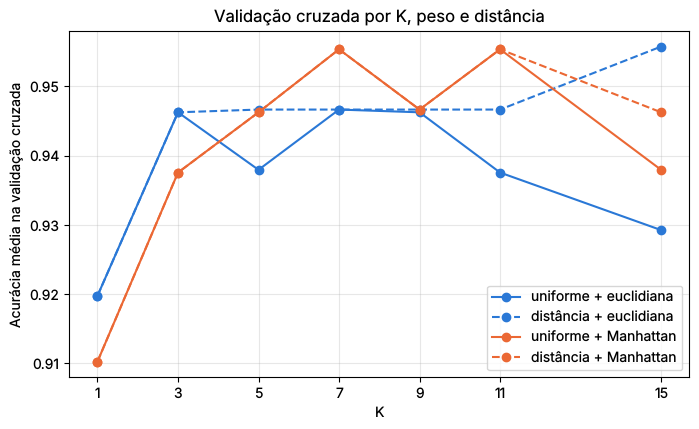

In [8]:
res = pd.DataFrame(busca.cv_results_)
res['configuração'] = (res['param_knn__weights'].map({'uniform': 'uniforme', 'distance': 'distância'})
                       + ' + ' + res['param_knn__p'].map({1: 'Manhattan', 2: 'euclidiana'}))
comparacao = res.pivot_table(index='param_knn__n_neighbors', columns='configuração',
                             values='mean_test_score').rename_axis('K')
display(comparacao.round(3))

estilos = {'uniforme + euclidiana': ('#2a78d6', '-'), 'distância + euclidiana': ('#2a78d6', '--'),
           'uniforme + Manhattan': ('#eb6834', '-'), 'distância + Manhattan': ('#eb6834', '--')}
fig, ax = plt.subplots(figsize=(8, 4.5))
for nome, (cor, linha) in estilos.items():
    ax.plot(comparacao.index, comparacao[nome], color=cor, linestyle=linha, marker='o', label=nome)
ax.set_xticks(valores_k)
ax.set_xlabel('K')
ax.set_ylabel('Acurácia média na validação cruzada')
ax.set_title('Validação cruzada por K, peso e distância')
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## 8. Comparação com uma Árvore de Decisão (mesmo particionamento)

,modelo,parâmetros,acurácia validação,acurácia teste
0,KNN,"K=15, weights=distance, p=2",0.956,0.974
1,Árvore de Decisão,max_depth=3,0.946,0.921


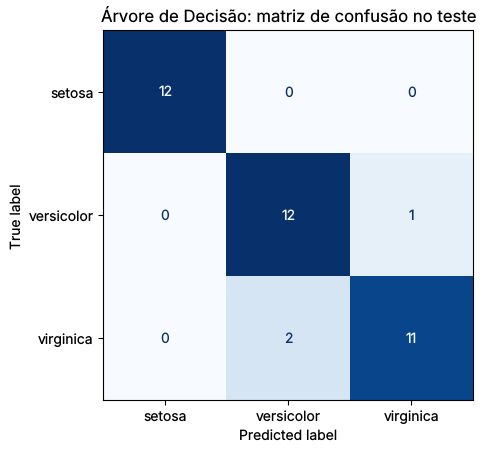

In [9]:
busca_arvore = GridSearchCV(DecisionTreeClassifier(random_state=123),
                            {'max_depth': [1, 2, 3, 4, 5, None]}, cv=cv, scoring='accuracy')
busca_arvore.fit(X_treino, y_treino)
y_prev_arvore = busca_arvore.predict(X_teste)

melhor = busca.best_params_
resultados = pd.DataFrame({
    'modelo': ['KNN', 'Árvore de Decisão'],
    'parâmetros': [f"K={melhor['knn__n_neighbors']}, weights={melhor['knn__weights']}, p={melhor['knn__p']}",
                   f"max_depth={busca_arvore.best_params_['max_depth']}"],
    'acurácia validação': [busca.best_score_, busca_arvore.best_score_],
    'acurácia teste': [accuracy_score(y_teste, y_prev), accuracy_score(y_teste, y_prev_arvore)]})
display(resultados.round(3))

ConfusionMatrixDisplay.from_predictions(y_teste, y_prev_arvore, display_labels=iris.target_names,
                                        cmap='Blues', colorbar=False)
plt.title('Árvore de Decisão: matriz de confusão no teste')
plt.show()

## 9. Conclusão

- **Desempenho:** a validação escolheu **K=15, peso por distância e distância euclidiana** (0,956 na validação). No teste o modelo acertou **37 de 38 flores (acurácia 0,974; precisão, recall e F1 macro ≈ 0,97)**. O único erro foi uma versicolor prevista como virginica. A setosa não teve erros.
- **Sensibilidade a K:** com K=1 a acurácia de treino é 1,000 porque cada flor é vizinha de si mesma, ou seja, o modelo memoriza. De K=3 a K=15, a melhor validação de cada K fica entre 0,946 e 0,956. São diferenças de uma ou duas flores, então vários valores de K são equivalentes.
- **Pesos e distância:** o peso por distância nunca piorou a validação e ajudou mais com K grande (em K=15, 0,956 contra 0,929 com peso uniforme). Entre euclidiana e Manhattan não houve vencedor fixo.
- **Normalização:** as quatro medidas estão em cm e têm escalas parecidas (desvio de 0,44 a 1,77 cm), então aqui a padronização pesa menos do que em bases com unidades diferentes. Ela fica dentro do pipeline para que nenhum atributo domine a distância e para ser ajustada só com o treino.
- **KNN × Árvore:** a árvore (max_depth=3) acertou 35 de 38 (0,921). A diferença para o KNN é de 2 flores, pequena demais para afirmar que um algoritmo é superior.
- **Limitações e generalização:** o teste tem só 38 flores (cada uma vale 2,6 pontos), e a Iris é pequena, limpa e balanceada, um cenário favorável ao KNN. O KNN também guarda todo o treino e calcula distâncias a cada previsão, o que fica caro em bases grandes. A proximidade entre validação (0,956) e teste (0,974) indica boa generalização para flores da mesma população, mas o número exato depende do sorteio treino/teste.